# Virtual Care Analytics: from raw data to executive dashboard

This notebook walks through the whole project in one place: the source data, the problems hidden in it, how the Snowflake layers clean and govern it, and how the numbers on the Power BI dashboard reconcile back to the raw files.

**All data is synthetic.** *Cascade Virtual Care* is a fictional telehealth company. Every member, employer and provider is generated by [`scripts/generate_data.py`](../scripts/generate_data.py) with a fixed seed, so the results are reproducible.

| Section | What it shows |
|---|---|
| 1. Source data | Six CSV extracts and their volumes |
| 2. Planted problems | The data-quality issues the pipeline has to catch |
| 3. Cleaning | The STAGING logic, mirrored in pandas |
| 4. Reconciliation | Every dashboard KPI recomputed from the raw files |
| 5. The story in the data | Growth, revenue mix and the link between wait time and satisfaction |
| 6. The Snowflake build | Scripts, governance and data quality, with screenshots |
| 7. The Power BI layer | Semantic model and dashboard |
| 8. Production next steps | What would change for a real deployment |

**Architecture:** CSV extracts → `RAW` (landed as-is) → `STAGING` (typed, deduplicated, flagged) → `ANALYTICS` (star schema) → Power BI and a Snowflake semantic view for Cortex Analyst. Governance (masking, row access, data quality checks) is applied in Snowflake, so it travels with the data. Details in [`docs/architecture.md`](../docs/architecture.md).

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

DATA = Path("../data")

# Chart style: one teal for single series, a validated 3-color categorical set, recessive axes
TEAL, CORAL, VIOLET = "#00809A", "#D9534F", "#8A6FC2"
INK, MUTED, GRID = "#1F2937", "#6B7280", "#E5E7EB"
plt.rcParams.update({
    "figure.dpi": 110, "figure.figsize": (9, 4.2), "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.titlelocation": "left", "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "legend.frameon": False, "axes.axisbelow": True,
})
pd.set_option("display.width", 120)

## 1. Source data

Six extracts, as a source system would hand them over. The visits file is the fact; the rest describe who, where and what.

In [2]:
files = ["employers", "members", "providers", "service_lines", "visits", "surveys"]
raw = {f: pd.read_csv(DATA / f"{f}.csv") for f in files}
pd.DataFrame({"rows": {f: len(df) for f, df in raw.items()},
              "columns": {f: df.shape[1] for f, df in raw.items()}})

,rows,columns
employers,24,8
members,6000,12
providers,106,8
service_lines,7,5
visits,45040,17
surveys,15049,6


In [3]:
visits = raw["visits"]
visits["requested_at"] = pd.to_datetime(visits["requested_at"])
print(f"Visits run from {visits.requested_at.min():%b %d, %Y} to {visits.requested_at.max():%b %d, %Y}")
visits.head(3)

Visits run from Jan 01, 2025 to Oct 31, 2026


,visit_id,member_id,provider_id,service_line_id,channel,diagnosis_category,requested_at,started_at,ended_at,wait_minutes,duration_minutes,visit_status,resolved_first_contact,referral_flag,prescription_flag,er_followup_7d,visit_cost
0,V0000001,M001037,P0091,6,Video,A1c review,2025-06-14 17:28:00,2025-06-14 17:40:00,2025-06-14 18:01:00,12.0,21.0,Completed,1,0,1,0,106.33
1,V0000002,M001157,P0067,3,Video,Medication management - depression,2025-06-28 06:05:00,2025-06-28 06:22:00,2025-06-28 06:50:00,17.0,28.0,Completed,1,0,0,0,234.03
2,V0000003,M004194,P0099,7,Video,Medication adjustment - BP,2026-09-24 21:04:00,2026-09-24 21:27:00,2026-09-24 21:42:00,23.0,15.0,Completed,1,0,1,0,110.48


## 2. The planted problems

Real source data is never clean, so the generator plants five kinds of issue. Finding them here first means the Snowflake checks can be tested against a known answer.

In [4]:
members, providers = raw["members"], raw["providers"]
dedup = visits.drop_duplicates("visit_id")
email_ok = members["email"].str.lower().str.match(r"^[a-z0-9._%+-]+@[a-z0-9.-]+\.[a-z]{2,}$", na=False)

issues = pd.DataFrame([
    ("Visits",  "Uniqueness",            "Duplicate visit rows in source",   len(visits) - len(dedup),                           len(visits)),
    ("Visits",  "Referential integrity", "Visit references unknown provider", (~dedup.provider_id.isin(providers.provider_id)).sum(), len(dedup)),
    ("Visits",  "Validity",              "Negative visit duration",          (dedup.duration_minutes < 0).sum(),                  len(dedup)),
    ("Members", "Validity",              "Malformed email address",          (~email_ok).sum(),                                   len(members)),
    ("Members", "Completeness",          "Missing gender",                   members.gender.isna().sum(),                         len(members)),
], columns=["entity", "dimension", "check", "failed_rows", "total_rows"])
issues

,entity,dimension,check,failed_rows,total_rows
0,Visits,Uniqueness,Duplicate visit rows in source,40,45040
1,Visits,Referential integrity,Visit references unknown provider,74,45000
2,Visits,Validity,Negative visit duration,39,45000
3,Members,Validity,Malformed email address,22,6000
4,Members,Completeness,Missing gender,134,6000


These are the same counts the Snowflake data quality scorecard reports (`ANALYTICS.DQ_SCORECARD`), computed independently:

![Data quality scorecard in Snowflake](../docs/screenshots/data-quality-scorecard.png)

## 3. Cleaning: the STAGING logic, mirrored in pandas

The rule throughout is **flag, don't drop**: a bad row is kept, marked and handled, so totals always reconcile back to the source. In Snowflake this is [`snowflake/02_staging.sql`](../snowflake/02_staging.sql) and [`03_analytics.sql`](../snowflake/03_analytics.sql). The core of the deduplication there:

```sql
SELECT t.* EXCLUDE (rn, dup_count),
       IFF(t.dup_count > 1, 1, 0)                 AS dq_duplicate_in_source,
       IFF(p.provider_id IS NULL, 1, 0)           AS dq_orphan_provider,
       IFF(t.duration_minutes < 0, 1, 0)          AS dq_negative_duration
FROM typed t
LEFT JOIN STG_PROVIDERS p ON p.provider_id = t.provider_id
WHERE t.rn = 1;   -- one row per visit_id
```

In [5]:
fact = dedup.copy()
fact["provider_id"] = fact["provider_id"].where(fact.provider_id.isin(providers.provider_id), "P-UNKNOWN")
fact["duration_minutes"] = fact["duration_minutes"].mask(fact.duration_minutes < 0)   # impossible values -> NULL
fact = fact.merge(raw["service_lines"], on="service_line_id", how="left")
completed = fact[fact.visit_status == "Completed"]

assert len(fact) == 45_000, "45,040 source rows minus 40 duplicates"
print(f"{len(visits):,} source rows -> {len(fact):,} visits after deduplication")
fact.visit_status.value_counts().to_frame("visits")

45,040 source rows -> 45,000 visits after deduplication


,visits
visit_status,
Completed,39739
Cancelled,3150
No-Show,2111


## 4. Reconciliation: does the dashboard tell the truth?

Every KPI on the Executive Overview, recomputed from the raw CSVs with the same definitions as the DAX measures in [`powerbi/measures.dax`](../powerbi/measures.dax).

In [6]:
surveys = raw["surveys"].drop_duplicates("survey_id")
surveys = surveys[surveys.visit_id.isin(fact.visit_id)]
nps = ((surveys.nps_score >= 9).mean() - (surveys.nps_score <= 6).mean()) * 100

kpis = pd.DataFrame([
    ("Completed Visits",           f"{len(completed):,}",                           "40K"),
    ("Unique Members",             f"{completed.member_id.nunique():,}",            "6K"),
    ("Avg Wait (min)",             f"{completed.wait_minutes.mean():.1f}",          "16.0"),
    ("First Contact Resolution %", f"{completed.resolved_first_contact.mean():.1%}", "86.4%"),
    ("NPS",                        f"{nps:.0f}",                                     "15"),
    ("Visit Revenue",              f"${fact.visit_cost.sum():,.0f}",                "$4M"),
], columns=["KPI", "Recomputed from raw files", "Dashboard shows"])
kpis

,KPI,Recomputed from raw files,Dashboard shows
0,Completed Visits,"39,739",40K
1,Unique Members,"5,919",6K
2,Avg Wait (min),16.0,16.0
3,First Contact Resolution %,86.4%,86.4%
4,NPS,15,15
5,Visit Revenue,"$4,119,808",$4M


Every figure matches. The dashboard is a faithful view of the source, after cleaning.

![Executive Overview](../docs/screenshots/executive-overview.png)

## 5. The story in the data

### Volume is growing year over year

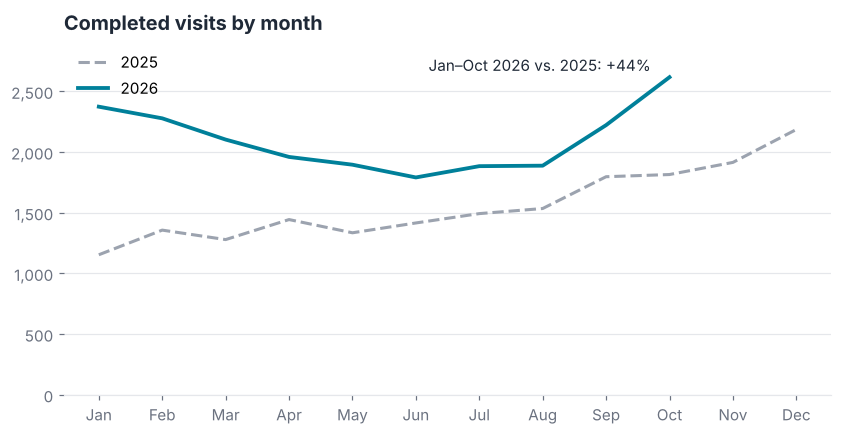

In [7]:
monthly = completed.assign(year=completed.requested_at.dt.year, month=completed.requested_at.dt.month)
monthly = monthly.groupby(["year", "month"]).size().unstack(0)

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly[2025], color="#9CA3AF", lw=2, ls="--", label="2025")
ax.plot(monthly.index, monthly[2026], color=TEAL, lw=2.5, label="2026")
ax.set_xticks(range(1, 13), ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))
ax.set_title("Completed visits by month")
ax.legend(loc="upper left")
growth = monthly.loc[1:10, 2026].sum() / monthly.loc[1:10, 2025].sum() - 1
ax.annotate(f"Jan–Oct 2026 vs. 2025: {growth:+.0%}", xy=(10, monthly.loc[10, 2026]), xytext=(6.2, monthly[2026].max() * 1.02),
            color=INK, fontsize=10)
ax.set_ylim(0, monthly.max().max() * 1.12)
plt.show()

### Behavioral health punches above its weight

General and urgent care drives the most visits, but behavioral health earns a far bigger share of revenue than of volume, because therapy and psychiatry visits are longer and priced higher.

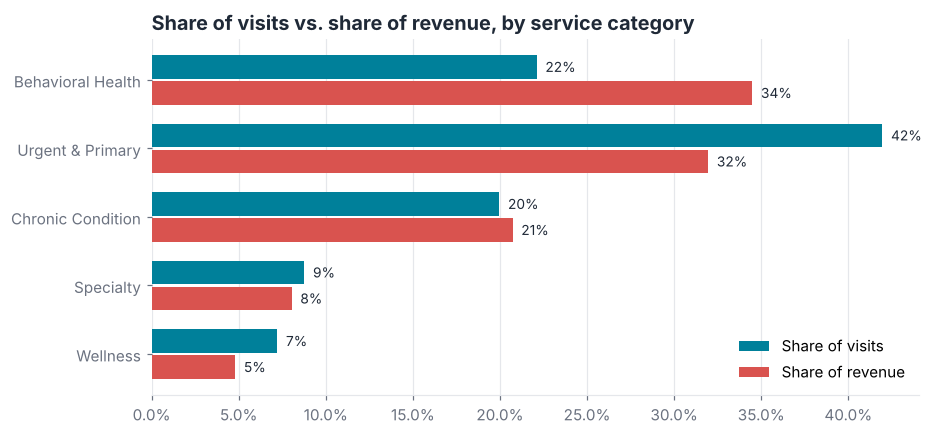

In [8]:
mix = completed.groupby("service_category").agg(visits=("visit_id", "count"), revenue=("visit_cost", "sum"))
share = (mix / mix.sum()).sort_values("revenue")

fig, ax = plt.subplots(figsize=(9, 4.2))
y = range(len(share))
h = 0.38
ax.barh([i + h/2 for i in y], share["visits"],  height=h - 0.04, color=TEAL,  label="Share of visits")
ax.barh([i - h/2 for i in y], share["revenue"], height=h - 0.04, color=CORAL, label="Share of revenue")
for i, (vv, rr) in enumerate(zip(share["visits"], share["revenue"])):
    ax.text(vv + 0.005, i + h/2, f"{vv:.0%}", va="center", color=INK, fontsize=9)
    ax.text(rr + 0.005, i - h/2, f"{rr:.0%}", va="center", color=INK, fontsize=9)
ax.set_yticks(list(y), share.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_title("Share of visits vs. share of revenue, by service category")
ax.legend(loc="lower right")
plt.show()

### Waits sit just over target, and the scheduled programs drive the gap

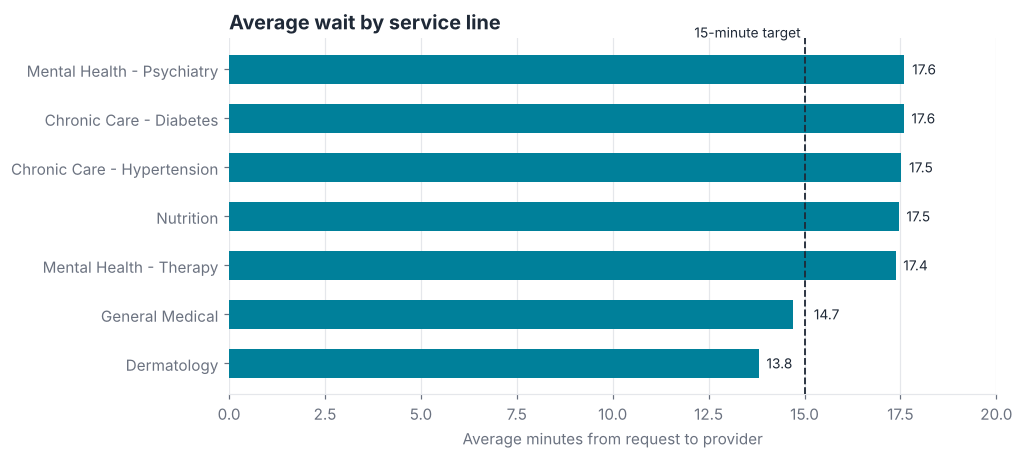

In [9]:
wait = completed.groupby("service_line_name").wait_minutes.mean().sort_values()

fig, ax = plt.subplots()
ax.barh(wait.index, wait.values, color=TEAL, height=0.6)
for i, w in enumerate(wait.values):
    ax.text(w + (0.55 if 14 < w < 15.3 else 0.2), i, f"{w:.1f}", va="center", color=INK, fontsize=9)
ax.axvline(15, color=INK, lw=1.2, ls="--", zorder=3)
ax.text(15, len(wait) - 0.35, "15-minute target ", color=INK, fontsize=9, ha="right")
ax.set_xlim(0, 20)
ax.grid(axis="y", visible=False); ax.grid(axis="x", visible=True)
ax.set_xlabel("Average minutes from request to provider")
ax.set_title("Average wait by service line")
plt.show()

### Wait time is the satisfaction lever

The generator models satisfaction as falling with wait time. Joining surveys to visits shows how strongly that plays out: members seen within 15 minutes are promoters on balance, and members who wait more than 30 minutes are overwhelmingly detractors. That makes the wait-time target a customer-experience metric, not just an operations one.

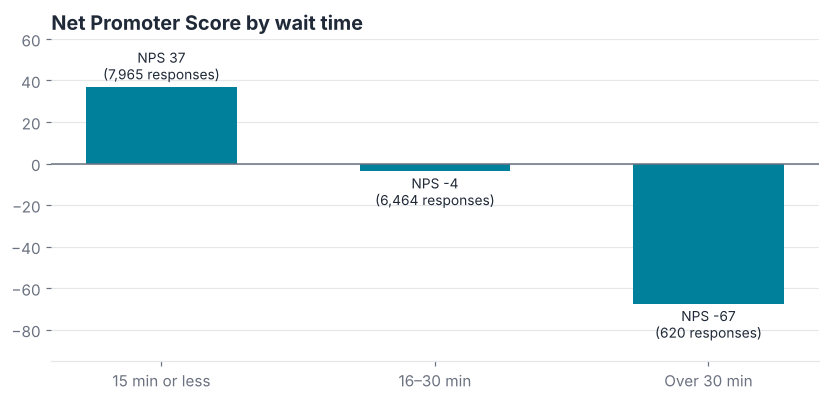

,responses,nps
wait_band,,
15 min or less,7965,37.0
16–30 min,6464,-3.6
Over 30 min,620,-67.4


In [10]:
sv = surveys.merge(completed[["visit_id", "wait_minutes"]], on="visit_id")
sv["wait_band"] = pd.cut(sv.wait_minutes, [0, 15, 30, 10_000], labels=["15 min or less", "16–30 min", "Over 30 min"])
by_band = sv.groupby("wait_band", observed=True).agg(
    responses=("survey_id", "count"),
    nps=("nps_score", lambda s: ((s >= 9).mean() - (s <= 6).mean()) * 100))

fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.bar(by_band.index.astype(str), by_band.nps, color=TEAL, width=0.55)
for b, (n, r) in zip(bars, zip(by_band.nps, by_band.responses)):
    ax.text(b.get_x() + b.get_width()/2, n + (2 if n >= 0 else -2), f"NPS {n:.0f}\n({r:,} responses)",
            ha="center", va="bottom" if n >= 0 else "top", color=INK, fontsize=9)
ax.axhline(0, color=MUTED, lw=1)
ax.set_ylim(-95, 60)
ax.set_title("Net Promoter Score by wait time")
plt.show()
by_band.round(1)

## 6. The Snowflake build

Every layer is a numbered, commented script in [`snowflake/`](../snowflake/), run in order, with a teardown script to rebuild from scratch.

| Script | What it does |
|---|---|
| `00_setup.sql` | Roles, separate ELT and BI warehouses, a resource monitor, database and schemas, the Power BI service user, the landing stage |
| `01_raw_load.sql` | Lands the CSVs as text with file-level lineage |
| `02_staging.sql` | Types, deduplicates and flags every row |
| `03_analytics.sql` | Builds the star schema: `FACT_VISIT`, `FACT_SURVEY` and five dimensions |
| `04_governance.sql` | Tags, masking, row access, data metric functions, the DQ scorecard |
| `05_semantic_view.sql` | Semantic view for Cortex Analyst |
| `06_validate_governance.sql` | Proves the controls per role |

![Snowsight workspace](../docs/screenshots/snowsight-workspace.png)

### Governance: masking follows the tag

One policy per data type, attached to a `PII_TYPE` tag. Tag a new column and it is protected automatically:

```sql
CREATE MASKING POLICY MASK_PII_STRING AS (val STRING) RETURNS STRING ->
  CASE
    WHEN IS_ROLE_IN_SESSION('VC_PHI_READER') THEN val
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('VIRTUAL_CARE_DEMO.GOVERNANCE.PII_TYPE') = 'EMAIL'
      THEN REGEXP_REPLACE(val, '^[^@]+', '*****')
    WHEN SYSTEM$GET_TAG_ON_CURRENT_COLUMN('VIRTUAL_CARE_DEMO.GOVERNANCE.PII_TYPE') = 'PHONE'
      THEN '***-***-' || RIGHT(val, 4)
    ELSE '*** MASKED ***'
  END;

ALTER TAG PII_TYPE SET MASKING POLICY MASK_PII_STRING, MASKING POLICY MASK_PII_DATE;
```

### Governance: row access from an entitlements table

Adding a regional analyst is an `INSERT`, not a policy change, and a role with no entitlement sees nothing:

```sql
CREATE ROW ACCESS POLICY REGION_RAP AS (row_region STRING) RETURNS BOOLEAN ->
  IS_ROLE_IN_SESSION('VC_ENGINEER')
  OR EXISTS (SELECT 1 FROM GOVERNANCE.REGION_ENTITLEMENTS e
             WHERE IS_ROLE_IN_SESSION(e.role_name)
               AND (e.region = 'ALL' OR e.region = row_region));
```

Signed in as a West-region analyst, the same `DIM_MEMBER` query returns masked fields and only West rows:

![West analyst: masked fields](../docs/screenshots/governance-west-analyst-masked.png)

![West analyst: West rows only](../docs/screenshots/governance-west-only-rows.png)

### Conversational AI on the same rules

`05_semantic_view.sql` defines the metrics once, with business synonyms, so Cortex Analyst can turn "What's the average wait by service line in each region?" into SQL. Because it reads the governed tables, AI answers inherit the same masking and row access.

![Semantic view query](../docs/screenshots/semantic-view-query.png)

## 7. The Power BI layer

Power BI connects through a least-privilege, key-pair service account (`PBI_SVC`), in Import mode. The masking holds all the way into the report, and the personal-data columns are never imported at all:

![Masked member data in Power BI](../docs/screenshots/powerbi-masked-member-preview.png)

The semantic model is a clean star schema: 10 single-direction, many-to-one relationships, a marked date table, and DAX measures for volume, access, quality, experience and year-over-year comparison ([`powerbi/measures.dax`](../powerbi/measures.dax), design notes in [`powerbi/model-design.md`](../powerbi/model-design.md)).

![Power BI model view](../docs/screenshots/powerbi-model-view.png)

Every visual responds to the date, region and service line filters. Here, West region, General Medical only:

![Filtered dashboard](../docs/screenshots/executive-overview-west-general-medical.png)

## 8. Production next steps

- **Transformations:** move the CTAS steps to dbt models or Snowflake Dynamic Tables with a target lag, with tests that assert the same reconciliation shown in section 4.
- **CI/CD:** deploy Snowflake objects from Git, and promote the Power BI project (`.pbip`) through deployment pipelines.
- **Per-user security:** Microsoft Entra ID SSO with DirectQuery would let each viewer query Snowflake as themselves, so row access applies per person instead of through Power BI roles.
- **Data quality alerting:** route Data Metric Function results to the owning team when a threshold is crossed.
- **Conversational AI:** add the semantic view as a tool on a Snowflake Intelligence agent, with verified queries for the most common questions.

<details><summary>Querying the live Snowflake build from Python (not run here)</summary>

```python
import os, snowflake.connector
from cryptography.hazmat.primitives import serialization

key = serialization.load_pem_private_key(open(os.environ["SNOWFLAKE_KEY_PATH"], "rb").read(), password=None)
conn = snowflake.connector.connect(
    account=os.environ["SNOWFLAKE_ACCOUNT"], user="PBI_SVC", private_key=key,
    role="VC_PBI_SERVICE", warehouse="VC_BI_WH", database="VIRTUAL_CARE_DEMO")
pd.read_sql("""
    SELECT * FROM SEMANTIC_VIEW(SEMANTIC.VIRTUAL_CARE_SV
      DIMENSIONS service_lines.service_line_name
      METRICS visits.total_visits, visits.avg_wait_minutes)""", conn)
```
</details>